# Client A notebook

Vicky - data prep. Zac - Client A strategy.

In [2]:
from IPython.display import display, Math, Latex

import pandas as pd
import numpy as np
import numpy_financial as npf
import yfinance as yf
import matplotlib.pyplot as plt
import random
from datetime import datetime

## Vicky - Data prep

Gets the stock data, checks which tickers are eligible and converts prices to CAD.

In [3]:
import time  # not in the given import cell; needed for time.sleep

GROUP_NUMBER = "6"        
TICKER_FILE = "Tickers.csv"

PURCHASE_DATE = pd.Timestamp("2026-11-27")
# Competition holding window (used to find earnings reports during the competition)
HOLD_START = pd.Timestamp("2026-11-27 16:00", tz="America/New_York")
HOLD_END   = pd.Timestamp("2026-12-04 16:00", tz="America/New_York")

# Price history to download: must start before the volume window and cover a year of signals
HISTORY_START = pd.Timestamp("2024-10-01")

# Volume rule
VOLUME_START = pd.Timestamp("2025-10-01")
VOLUME_END   = pd.Timestamp("2026-09-30")
MIN_AVG_VOLUME = 5000
MIN_TRADING_DAYS_IN_MONTH = 18

# Client mandates
CLIENT_BUDGETS = {"A": 1_000_000, "B": 750_000}       # CAD
CLIENT_N_STOCKS = {"A": 12, "B": 20}                   # our chosen portfolio sizes
MIN_STOCKS, MAX_STOCKS = 10, 20
MAX_STOCK_WEIGHT = 0.15
MAX_SECTOR_WEIGHT = 0.40

# Transaction fee: the smaller of US$2.15 and US$0.001 per share, for every stock
MAX_FEE_USD = 2.15
FEE_PER_SHARE_USD = 0.001
SAFETY_BUFFER_CAD = 0.01     # leave one cent unspent so rounding can never exceed the budget

# Eligibility (yfinance codes)
ALLOWED_QUOTE_TYPES = ["EQUITY"]
ALLOWED_CURRENCIES  = ["CAD", "USD"]
US_EXCHANGES = ["NMS", "NGM", "NCM", "NYQ", "ASE", "PCX", "BTS"]  # Nasdaq tiers, NYSE, NYSE American, NYSE Arca, Cboe
CA_EXCHANGES = ["TOR", "VAN", "NEO", "CNQ"]                       # TSX, TSX Venture, Cboe Canada, CSE
# OTC / pink-sheet codes are deliberately excluded: they are not exchange listings.
MAX_STALE_DAYS = 5           # last price older than this before the purchase date = not trading

# Strategy parameters
TRADING_DAYS_PER_YEAR = 252
LOOKBACK_DAYS = 252          # one year: Client B volatility and the equal-weight comparison period
MOMENTUM_DAYS = 126          # about six months
SHORT_MOMENTUM_DAYS = 20     # about one month
TREND_DAYS = 50              # 50-day moving average trend filter
CATALYST_BONUS = 0.10        # score bonus for Client A stocks with earnings in the window and positive momentum

BENCHMARK_TICKERS = {"US": "^GSPC", "CA": "^GSPTSE"}  # S&P 500 and S&P/TSX Composite
FX_TICKER = "CAD=X"          # CAD per 1 USD
PAUSE_SECONDS = 0.2          # pause between per-ticker requests to avoid rate limits





## read the ticker file and collect company information

def read_tickers(path):
    """Read the ticker file (one ticker per row, no header) in order to return a clean, de-duplicated list."""
    raw = pd.read_csv(path, header=None) ## pd haven't touched the data
    tickers = (raw.iloc[:, 0].dropna().astype(str)
               .str.strip().str.upper())
    tickers = tickers[tickers != ""].drop_duplicates()
    return list(tickers)


def get_stock_info(tickers):
    """Looking up quote type, exchange, currency and sector for each ticker.
    Tickers that yfinance cannot find will result in empty values (they fail the checks later)."""
    rows = []
    for ticker in tickers:
        try:
            info = yf.Ticker(ticker).info
        except Exception:
            info = {}
        rows.append({
            "Ticker": ticker,
            "SecurityType": info.get("quoteType"),
            "Exchange": info.get("exchange"),
            "Currency": info.get("currency"),
            "Sector": info.get("sector"),
            "Name": info.get("longName") or info.get("shortName"),
        })
        time.sleep(PAUSE_SECONDS)
    return pd.DataFrame(rows).set_index("Ticker")


def market_of(exchange):
    """Return 'US', 'CA' or None depending on where the stock is listed."""
    if pd.isna(exchange):
        return None
    if exchange in US_EXCHANGES:
        return "US"
    if exchange in CA_EXCHANGES:
        return "CA"
    return None



## download price and volume history
#### Use auto_adjust=False and Close column


def download_history(tickers, start, end):
    """Download daily closes and volumes
       return into two DFs (dates x tickers)"""

    data = yf.download(tickers, start=start, end=end + pd.Timedelta(days=1),
                       auto_adjust=False, progress=False, group_by="column")

    closes = data["Close"]
    volumes = data["Volume"]
    # With one ticker yfinance can return a Series; make it a DataFrame either way
    if isinstance(closes, pd.Series):
        closes = closes.to_frame(tickers[0])
        volumes = volumes.to_frame(tickers[0])
    closes.index = pd.to_datetime(closes.index).tz_localize(None)
    volumes.index = pd.to_datetime(volumes.index).tz_localize(None)
    return closes, volumes 



def get_fx_rate(index, start, end):
    """CAD per USD, lined up with the stock dates (forward-filled over holidays)."""
    fx = yf.download(FX_TICKER, start=start, end=end + pd.Timedelta(days=1),
                     auto_adjust=False, progress=False)["Close"]
    if isinstance(fx, pd.DataFrame):
        fx = fx.iloc[:, 0]
    fx.index = pd.to_datetime(fx.index).tz_localize(None)
    return fx.reindex(fx.index.union(index)).ffill().reindex(index).rename("USDCAD")



def convert_to_cad(closes_local, currencies, fx):
    """Multiply USD-quoted columns by the daily exchange rate; CAD columns stay as they are."""
    prices_cad = closes_local.copy()
    for ticker in closes_local.columns:
        if currencies.get(ticker) == "USD":
            prices_cad[ticker] = closes_local[ticker] * fx
    return prices_cad




## Volume Rule
## A "trading day" is a day the stock actually has a volume record. Because TSX and US holidays differ, each stock is counted on its own calendar.
## The average is taken over all remaining days (not an average of monthly averages).


def average_volume(volume_series, start, end, min_days):
    """Average daily volume over [start, end], excluding months with fewer than min_days trading days."""
    v = volume_series.loc[start:end].dropna()
    if v.empty:
        return np.nan
    month = v.index.to_period("M")
    days_per_month = v.groupby(month).count()
    full_months = days_per_month[days_per_month >= min_days].index
    v = v[month.isin(full_months)]
    return v.mean() if not v.empty else np.nan


## Eligibility check + load_stock_data()
def check_eligibility(info, closes_local, volumes, as_of):
    """Add AvgVolume, Eligible and Reason columns. Every failed rule is listed in Reason."""
    result = info.copy()
    result["Market"] = result["Exchange"].apply(market_of)
    result["AvgVolume"] = np.nan
    result["Eligible"] = False
    result["Reason"] = ""

    for ticker in result.index:
        problems = []
        row = result.loc[ticker]

        if pd.isna(row["SecurityType"]):
            # yfinance found nothing: report one clear reason and skip the other checks
            result.loc[ticker, "Reason"] = "invalid ticker (no data found)"
            continue
        if row["SecurityType"] not in ALLOWED_QUOTE_TYPES:
            problems.append(f"not a company stock ({row['SecurityType']})")
        if pd.isna(row["Market"]):
            problems.append(f"not listed on a Canadian/US exchange ({row['Exchange']})")
        if row["Currency"] not in ALLOWED_CURRENCIES:
            problems.append(f"currency not CAD/USD ({row['Currency']})")

        if ticker in closes_local.columns:
            prices = closes_local[ticker].dropna()
            last_date = prices.index.max() if not prices.empty else None
            check_date = min(as_of, pd.Timestamp.today().normalize())
            if last_date is None or (check_date - last_date).days > MAX_STALE_DAYS:
                problems.append("no recent price (possibly delisted)")
            avg_vol = average_volume(volumes[ticker], VOLUME_START, VOLUME_END,
                                     MIN_TRADING_DAYS_IN_MONTH)
            result.loc[ticker, "AvgVolume"] = avg_vol
            if pd.isna(avg_vol) or avg_vol < MIN_AVG_VOLUME:
                problems.append(f"average volume below {MIN_AVG_VOLUME:,}")
        else:
            problems.append("no price data")

        result.loc[ticker, "Eligible"] = len(problems) == 0
        result.loc[ticker, "Reason"] = "; ".join(problems)
    return result


def load_stock_data(path, as_of=PURCHASE_DATE):
    """Read tickers, check eligibility and download history.
    Returns a dictionary with the screening table and all historical tables."""
    tickers = read_tickers(path)
    print(f"Read {len(tickers)} unique tickers from {path}")

    info = get_stock_info(tickers)
    found = [t for t in tickers if pd.notna(info.loc[t, "SecurityType"])]
    closes_local, volumes = download_history(found, HISTORY_START, as_of)

    screening = check_eligibility(info, closes_local, volumes, as_of)
    eligible = list(screening.index[screening["Eligible"]])

    # Keep only eligible stocks in the price tables
    closes_local = closes_local[eligible].loc[:as_of]
    volumes = volumes[eligible].loc[:as_of]

    fx = get_fx_rate(closes_local.index, HISTORY_START, as_of)
    prices_cad = convert_to_cad(closes_local, screening["Currency"].to_dict(), fx)

    print(f"{len(eligible)} eligible, {len(tickers) - len(eligible)} excluded")
    return {
        "screening": screening,
        "eligible": eligible,
        "closes_local": closes_local,
        "volumes": volumes,
        "fx": fx,
        "prices_cad": prices_cad,
    }


## benchmarks in CAD

## Each stock is compared with home markets

def get_benchmarks_cad(index, fx, start, end):
    """Return a DataFrame with columns 'US' and 'CA', both in CAD, lined up with the stock dates."""
    symbols = list(BENCHMARK_TICKERS.values())
    closes, _ = download_history(symbols, start, end)
    closes = closes.reindex(closes.index.union(index)).ffill().reindex(index)
    benchmark_cad = pd.DataFrame(index=index)
    benchmark_cad["US"] = closes[BENCHMARK_TICKERS["US"]] * fx   # S&P 500 is in USD
    benchmark_cad["CA"] = closes[BENCHMARK_TICKERS["CA"]]        # TSX is already in CAD
    return benchmark_cad





## Catalysts
def earnings_in_window(timestamps, start=HOLD_START, end=HOLD_END):
    """Return the first earnings timestamp inside the window, or NaT."""
    for ts in sorted(timestamps):
        ts = pd.Timestamp(ts)
        if ts.tzinfo is None:
            ts = ts.tz_localize("America/New_York")
        else:
            ts = ts.tz_convert("America/New_York")
        if ts.hour == 0 and ts.minute == 0:      # time unknown: compare dates only
            if start.date() < ts.date() <= end.date():
                return ts
        elif start < ts < end:
            return ts
    return pd.NaT


def get_earnings_timestamps(ticker):
    """Collect earnings timestamps from get_earnings_dates(), falling back to .calendar."""
    stock = yf.Ticker(ticker)
    timestamps = []
    try:
        dates = stock.get_earnings_dates(limit=8)
        if dates is not None and len(dates) > 0:
            timestamps += list(dates.index)
    except Exception:
        pass
    if not timestamps:
        try:
            calendar = stock.calendar or {}
            timestamps += list(calendar.get("Earnings Date", []))
        except Exception:
            pass
    return timestamps


def get_catalysts(tickers):
    """Return a DataFrame with EarningsDate and CatalystStatus for each ticker."""
    rows = []
    for ticker in tickers:
        timestamps = get_earnings_timestamps(ticker)
        hit = earnings_in_window(timestamps)
        if pd.notna(hit):
            status = "Event"
        elif not timestamps:
            status = "Unknown"
        # Only say "NoEvent" if we can see an upcoming date (otherwise the data may just be stale)
        elif max(pd.Timestamp(t).tz_localize(None) if pd.Timestamp(t).tzinfo is None
                 else pd.Timestamp(t).tz_convert(None) for t in timestamps) > HOLD_START.tz_convert(None):
            status = "NoEvent"
        else:
            status = "Unknown"
        rows.append({"Ticker": ticker, "EarningsDate": hit, "CatalystStatus": status})
        time.sleep(PAUSE_SECONDS)
    return pd.DataFrame(rows).set_index("Ticker")



## Volatility

def window_return(prices, days):
    """Return over the last `days` trading days (prices must have no gaps)."""
    if len(prices) <= days:
        return np.nan
    return prices.iloc[-1] / prices.iloc[-1 - days] - 1


def calculate_signals(prices_cad, volumes, benchmark_cad, markets, as_of=PURCHASE_DATE):
    """Return a DataFrame of signals (one row per ticker), calculated as of `as_of`."""
    prices_cad = prices_cad.loc[:as_of]
    volumes = volumes.loc[:as_of]
    benchmark_cad = benchmark_cad.loc[:as_of]

    # Benchmark 20-day returns, using the benchmark's own trading days
    bench_return20 = {m: window_return(benchmark_cad[m].dropna(), 20) for m in benchmark_cad.columns}

    rows = []
    for ticker in prices_cad.columns:
        prices = prices_cad[ticker].dropna()
        daily_returns = prices.pct_change().dropna()
        vol = volumes[ticker].dropna()

        vol20 = daily_returns.tail(20).std() if len(daily_returns) >= 20 else np.nan
        vol60 = daily_returns.tail(60).std() if len(daily_returns) >= 60 else np.nan
        return20 = window_return(prices, 20)
        ma20 = prices.tail(20).mean() if len(prices) >= 20 else np.nan
        avg_vol_60 = vol.tail(60).mean() if len(vol) >= 60 else np.nan

        rows.append({
            "Ticker": ticker,
            "Vol20": vol20,
            "Vol60": vol60,
            "VolRatio": vol20 / vol60 if vol60 else np.nan,
            "Return5": window_return(prices, 5),
            "Return20": return20,
            "PriceVsMA20": prices.iloc[-1] / ma20 - 1 if ma20 else np.nan,
            "RelativeMomentum": return20 - bench_return20.get(markets.get(ticker), np.nan),
            "RelativeVolume": vol.tail(5).mean() / avg_vol_60 if avg_vol_60 else np.nan,
        })
    signals = pd.DataFrame(rows).set_index("Ticker")

    # Percentile ranks (0 to 1) make the signals comparable for Zac's scoring
    for column in ["Vol20", "Return20", "RelativeMomentum", "RelativeVolume"]:
        signals[column + "Rank"] = signals[column].rank(pct=True)
    return signals



## running everything

data = load_stock_data(TICKER_FILE)
screening = data["screening"]

# Show what was excluded and why
exclusions = screening.loc[~screening["Eligible"], ["SecurityType", "Exchange", "Currency", "Reason"]]
print(f"\nExcluded {len(exclusions)} tickers:")
display(exclusions)

Read 40 unique tickers from Tickers.csv


$MON: possibly delisted; no timezone found
$BK: possibly delisted; no price data found  (1d 2024-10-01 00:00:00 -> 2026-11-28 00:00:00)
$RTN: possibly delisted; no timezone found
$AGN: possibly delisted; no timezone found
$CELG: possibly delisted; no timezone found

5 Failed downloads:
['MON', 'RTN', 'AGN', 'CELG']: possibly delisted; no timezone found
['BK']: possibly delisted; no price data found  (1d 2024-10-01 00:00:00 -> 2026-11-28 00:00:00)


35 eligible, 5 excluded

Excluded 5 tickers:


,SecurityType,Exchange,Currency,Reason
Ticker,,,,
AGN,NONE,NaN,NaN,not a company stock (NONE); not listed on a Ca...
BK,EQUITY,NYQ,NaN,currency not CAD/USD (nan); no recent price (p...
CELG,NONE,NaN,NaN,not a company stock (NONE); not listed on a Ca...
MON,NONE,NaN,NaN,not a company stock (NONE); not listed on a Ca...
RTN,NONE,NaN,NaN,not a company stock (NONE); not listed on a Ca...


## Client A - Zac

Test volatility, momentum and KNN using past 5-day returns. Then choose a strategy and buy the stocks.

In [4]:
# Past stock returns and volume
prices = data["prices_cad"]
markets = screening["Market"].to_dict()
benchmarks = get_benchmarks_cad(prices.index, data["fx"], HISTORY_START, prices.index[-1])
history = {}

for ticker in data["eligible"]:
    p = prices[ticker].dropna()
    v = data["volumes"][ticker].reindex(p.index)
    h = pd.DataFrame(index=p.index)
    h["R5"] = p / p.shift(5) - 1
    h["R20"] = p / p.shift(20) - 1
    h["Vol"] = p.pct_change().rolling(20).std()
    h["Volume"] = v.rolling(5).mean() / v.rolling(60).mean()
    h["Next5"] = p.shift(-5) / p - 1
    history[ticker] = h


def knn(ticker, day):
    h = history[ticker]
    if day not in h.index:
        return np.nan

    i = h.index.get_loc(day)
    cols = ["R5", "R20", "Vol", "Volume"]
    # Skip recent days since their future returns are not known yet
    past = h.iloc[:i-4].dropna()
    if len(past) < 30:
        return np.nan

    today = h.loc[day, cols]
    if today.isna().any():
        return np.nan

    scale = past[cols].std().replace(0, 1)
    distance = ((past[cols] - today) / scale) ** 2
    distance = distance.sum(axis=1)
    closest = distance.nsmallest(20).index
    return past.loc[closest, "Next5"].mean()

In [5]:
# Stock scores

def stock_scores(day):
    valid = []
    for ticker in data["eligible"]:
        p = prices[ticker].loc[:day].dropna()
        if len(p) >= 65 and day in p.index:
            valid.append(ticker)

    if len(valid) < 10:
        return pd.DataFrame()

    s = calculate_signals(prices[valid], data["volumes"][valid], benchmarks, markets, day)
    s["Sector"] = screening["Sector"]
    sector = s.groupby("Sector")["RelativeMomentum"].transform("mean")

    predictions = []
    for ticker in s.index:
        predictions.append(knn(ticker, day))

    s["SectorRank"] = sector.rank(pct=True)
    s["KNNRank"] = pd.Series(predictions, index=s.index).rank(pct=True).fillna(0.5)
    s["Volatility"] = s["Vol20Rank"]
    s["Momentum"] = (0.5 * s["Return20Rank"] + 0.3 * s["RelativeMomentumRank"]
                     + 0.2 * s["SectorRank"])
    s["KNN"] = (0.4 * s["KNNRank"] + 0.25 * s["Return20Rank"]
                + 0.2 * s["RelativeMomentumRank"] + 0.15 * s["SectorRank"])
    return s


def select_stocks(s, method):
    ranked = s.sort_values(method, ascending=False)

    sizes = list(range(CLIENT_N_STOCKS["A"], MAX_STOCKS + 1))
    sizes.extend(range(MIN_STOCKS, CLIENT_N_STOCKS["A"]))

    for n in sizes:
        chosen = []
        counts = {}

        for ticker in ranked.index:
            sector = s.loc[ticker, "Sector"]
            if pd.isna(sector) or pd.isna(s.loc[ticker, method]):
                continue
            if counts.get(sector, 0) >= int(n * MAX_SECTOR_WEIGHT):
                continue

            chosen.append(ticker)
            counts[sector] = counts.get(sector, 0) + 1
            if len(chosen) == n:
                break

        if len(chosen) != n:
            continue

        weights = pd.Series(0.5 / n, index=chosen)
        for ticker in chosen:
            sector = s.loc[ticker, "Sector"]
            same = []
            for t in chosen:
                if s.loc[t, "Sector"] == sector:
                    same.append(t)
            extra = min(1 - weights.sum(), MAX_STOCK_WEIGHT - weights[ticker],
                        MAX_SECTOR_WEIGHT - weights[same].sum())
            if extra > 0:
                weights[ticker] += extra

        if np.isclose(weights.sum(), 1):
            return chosen, weights

    raise ValueError("Could not build a valid Client A portfolio")

In [10]:
# Backtest the three strategies
results = []

for day in prices.index[125:-5:4]:
    s = stock_scores(day)
    if s.empty:
        continue

    row = {"Date": day}
    for method in ["Volatility", "Momentum", "KNN"]:
        try:
            chosen, weights = select_stocks(s, method)
        except ValueError:
            continue

        total = 0
        complete = True
        for ticker in chosen:
            result = history[ticker].loc[day, "Next5"]
            if pd.isna(result):
                complete = False
                break
            total = total + weights[ticker] * result
        if complete:
            row[method] = total

    results.append(row)

backtest = pd.DataFrame(results).set_index("Date").dropna()
if len(backtest) < 30:
    raise ValueError("Not enough historical periods to compare strategies")

split = int(len(backtest) * 0.8)
# Skip one date between training and testing so their 5-day returns do not overlap
training = backtest.iloc[:split-1]
testing = backtest.iloc[split:]
best = training.mean().idxmax()

print("Historical periods:", len(backtest))
print("Strategy selected:", best)
print("Later test returns (%):")
print((testing.mean() * 100).round(2))

# Buy the stocks using the best strategy
day = PURCHASE_DATE
if day not in prices.index:
    raise ValueError("November 27 closing prices are not available yet")
    
s = stock_scores(day)
chosen, weights = select_stocks(s, best)

cad = prices.loc[day, chosen]
local = data["closes_local"].loc[day, chosen]
fx = float(data["fx"].loc[day])
if cad.isna().any() or local.isna().any() or pd.isna(fx) or fx <= 0:
    raise ValueError("Missing closing prices or exchange rate")

budget = CLIENT_BUDGETS["A"]
money = budget - SAFETY_BUFFER_CAD

# Recalculate because fees depend on how many shares we buy
for i in range(5):
    shares = money * weights / cad
    fees = np.minimum(MAX_FEE_USD, FEE_PER_SHARE_USD * shares).sum() * fx
    money = budget - fees - SAFETY_BUFFER_CAD

shares = money * weights / cad
fees = np.minimum(MAX_FEE_USD, FEE_PER_SHARE_USD * shares).sum() * fx
Portfolio_Final_A = pd.DataFrame({
    "Ticker": chosen,
    "Price": local.values,
    "Currency": screening.loc[chosen, "Currency"].values,
    "Shares": shares.values,
    "Value": (shares * cad).values,
    "Weight": weights.values
}, index=range(1, len(chosen) + 1))

# Check our portfolio
assert MIN_STOCKS <= len(chosen) <= MAX_STOCKS
assert set(chosen).issubset(data["eligible"])
assert weights.max() <= MAX_STOCK_WEIGHT + 0.0000001
assert weights.groupby(screening.loc[chosen, "Sector"]).sum().max() <= MAX_SECTOR_WEIGHT + 0.0000001
assert np.isclose(weights.sum(), 1)
assert Portfolio_Final_A["Value"].sum() + fees <= budget

print("Purchase date:", day.date())
display(Portfolio_Final_A)
print("Fees:", round(fees, 2))
print("Cash left:", round(budget - Portfolio_Final_A["Value"].sum() - fees, 2))

Historical periods: 102
Strategy selected: Volatility
Later test returns (%):
Volatility    0.94
Momentum      0.61
KNN           0.57
dtype: float64


ValueError: November 27 closing prices are not available yet

## Client A: financial explanation

**Our Goal.** Client A has CAD 1,000,000 and is judged on how much the portfolio grows over the one-week competition
(close of Nov 27 to close of Dec 4). One week is short, so the decision is about which kind of stock is most likely
to move up in the next five trading days, not about long-run value.

**Why we test three strategies instead of picking one.** Each strategy is a different bet about short-term returns:
- **Volatility**: buy the stocks with the highest recent volatility (Vol20). Riskier stocks swing more, so in a
  rising market they tend to gain the most in a week. This is the classic risk and return trade-off: more risk,
  higher expected return, but a wider range of outcomes.
- **Momentum**: buy the stocks that went up the most over the last month, especially relative to their home market
  (S&P 500 for US stocks, TSX for Canadian stocks) and with a strong sector. The idea is that recent winners tend to
  keep winning for a while.
- **KNN (nearest neighbours)**: for each stock, find the 20 past days when its recent return, volatility and
  trading volume looked most like today, and average what happened in the five days after. This lets the data say
  what usually follows a setup like today's.

**How the winner is chosen.** We rebuild each strategy's portfolio about every four trading days over the past year
(about 100 periods) and record its actual next five-day return. The strategy with the best average return on the
first 80% of periods is selected. The last 20% is kept aside as a check that the result was not just luck in one
stretch of time. Choosing by rules, not by opinion, avoids hindsight bias in our choice.

**How the portfolio is built.** We hold 12 stocks (within the 10 to 20 allowed). Every stock starts at half an
equal weight, then the highest-ranked stocks are topped up to the 15% stock limit while keeping every sector at or
below 40%. This leans the portfolio toward our best ideas while keeping it diversified across sectors, so one bad
industry cannot sink the week. USD stocks are bought at the Nov 27 close converted with the Nov 27 USD/CAD rate.
Fees of the smaller of US\$2.15 and US\$0.001 per share are charged per stock and taken out of the budget first,
so the whole CAD 1,000,000 is spent except one cent.

**Main risk.** A short-horizon, high-weight portfolio can fall more than the market in a bad week. The equal-weight
comparison below shows what our concentration costs or earns compared with simply spreading the money evenly.

The cell below prints the numbers behind this explanation for the current run.

In [7]:
weights_A = Portfolio_Final_A.set_index("Ticker")["Weight"]
sectors_A = screening.loc[weights_A.index, "Sector"]
signals_A = s.loc[weights_A.index]

print("Strategy selected:", best)
print("Average 5-day return per strategy (%), training periods:")
print((training.mean() * 100).round(2).to_string())
print("Average 5-day return per strategy (%), held-out test periods:")
print((testing.mean() * 100).round(2).to_string())
print("Share of test periods where", best, "beat the other two:",
      f"{(testing.idxmax(axis=1) == best).mean():.0%}")

print("\nSector weights:")
print((weights_A.groupby(sectors_A).sum() * 100).round(1).sort_values(ascending=False).to_string())
print("\nMarket split (US vs Canada):")
print((weights_A.groupby(screening.loc[weights_A.index, "Market"]).sum() * 100).round(1).to_string())

print("\nChosen stocks compared with all eligible stocks (medians):")
all_signals = calculate_signals(prices, data["volumes"], benchmarks, markets, prices.index[-1])
compare = pd.DataFrame({
    "Client A": all_signals.loc[weights_A.index, ["Vol20", "Return20", "RelativeMomentum"]].median(),
    "All eligible": all_signals[["Vol20", "Return20", "RelativeMomentum"]].median(),
})
print((compare * 100).round(2).to_string())
print("(Vol20 = daily volatility over 20 days, Return20 and RelativeMomentum over 20 days, all in %)")

Strategy selected: Volatility
Average 5-day return per strategy (%), training periods:
Volatility    0.83
Momentum      0.74
KNN           0.53
Average 5-day return per strategy (%), held-out test periods:
Volatility    0.94
Momentum      0.61
KNN           0.57
Share of test periods where Volatility beat the other two: 48%

Sector weights:
Sector
Technology                40.0
Industrials               23.3
Communication Services    15.0
Healthcare                13.3
Consumer Cyclical          4.2
Financial Services         4.2

Market split (US vs Canada):
Market
CA    34.2
US    65.8

Chosen stocks compared with all eligible stocks (medians):
                  Client A  All eligible
Vol20                 3.42          2.05
Return20             -8.01         -3.63
RelativeMomentum     -0.80          3.51
(Vol20 = daily volatility over 20 days, Return20 and RelativeMomentum over 20 days, all in %)


## Client A: equal-weight comparison

We compare, over the past year (`LOOKBACK_DAYS` trading days before the purchase date) in a graph:
1. **Client A**: our 12 stocks with our weights
2. **Equal-weight Client A**: the same 12 stocks, 1/12 each (shows the effect of our weighting)
3. **Equal-weight all eligible**: every eligible stock, equal weights (shows the effect of our stock picking)
4. **S&P 500 (CAD)** and **TSX**, the home-market benchmarks

Portfolios are rebalanced to their weights daily, all in CAD. On a US or Canadian market holiday the closed
market's prices are carried forward (a 0% day). 

This looks backwards with today's choices, so it
describes the stocks we picked rather than predicting next week. Risk-free rate is taken as 0 for the
return per unit of risk.

Comparison period: 2025-11-26 to 2026-11-20 (252 trading days)


,Total return (%),Annualized return (%),Annualized volatility (%),Return / risk,Worst drop from peak (%),Best 5-day return (%),Worst 5-day return (%)
Client A,19.10,19.10,22.58,0.85,-16.75,11.50,-6.82
Equal-weight Client A,18.06,18.06,19.21,0.94,-13.67,7.89,-7.70
Equal-weight all eligible,17.26,17.26,13.20,1.31,-7.95,4.08,-6.31
S&P 500 (CAD),3.17,3.17,15.10,0.21,-11.13,5.29,-8.08
TSX,6.45,6.45,14.06,0.46,-10.19,4.17,-8.08


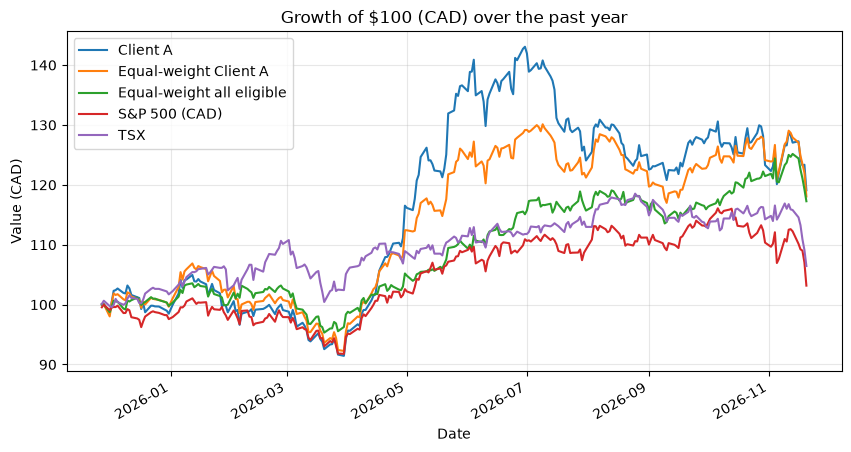

Our weighting vs equal weights on the same stocks: +1.04 percentage points of return, +3.37 points of volatility.
Our stock picks vs all eligible stocks (both equal weight): +0.80 percentage points of return, +6.01 points of volatility.


In [8]:
def performance(daily_returns):
    """Summary statistics for a Series of daily returns."""
    r = daily_returns.dropna()
    growth = (1 + r).cumprod()
    total = growth.iloc[-1] - 1
    ann_ret = (1 + total) ** (TRADING_DAYS_PER_YEAR / len(r)) - 1
    ann_vol = r.std() * np.sqrt(TRADING_DAYS_PER_YEAR)
    drawdown = (growth / growth.cummax() - 1).min()
    return pd.Series({
        "Total return (%)": total * 100,
        "Annualized return (%)": ann_ret * 100,
        "Annualized volatility (%)": ann_vol * 100,
        "Return / risk": ann_ret / ann_vol if ann_vol > 0 else np.nan,
        "Worst drop from peak (%)": drawdown * 100,
        "Best 5-day return (%)": ((1 + r).rolling(5).apply(np.prod, raw=True) - 1).max() * 100,
        "Worst 5-day return (%)": ((1 + r).rolling(5).apply(np.prod, raw=True) - 1).min() * 100,
    })


purchase_day = prices.index[-1]
# US and Canadian holidays differ: on the other market's holiday a stock's price simply did not change
window = prices.loc[:purchase_day].iloc[-(LOOKBACK_DAYS + 1):].ffill()
daily = window.pct_change().iloc[1:]
eligible_cols = [t for t in data["eligible"] if window[t].notna().all()]

comparison_returns = pd.DataFrame({
    "Client A": daily[weights_A.index].mul(weights_A, axis=1).sum(axis=1),
    "Equal-weight Client A": daily[weights_A.index].mean(axis=1),
    "Equal-weight all eligible": daily[eligible_cols].mean(axis=1),
    "S&P 500 (CAD)": benchmarks["US"].reindex(window.index).pct_change().iloc[1:],
    "TSX": benchmarks["CA"].reindex(window.index).pct_change().iloc[1:],
})

comparison_table = comparison_returns.apply(performance).T.round(2)
print(f"Comparison period: {window.index[0].date()} to {window.index[-1].date()} ({len(daily)} trading days)")
if len(eligible_cols) < len(data["eligible"]):
    print("Left out of 'all eligible' (not a full year of prices):",
          sorted(set(data["eligible"]) - set(eligible_cols)))
display(comparison_table)

growth = (1 + comparison_returns.fillna(0)).cumprod() * 100
growth.plot(figsize=(10, 5), title="Growth of $100 (CAD) over the past year")
plt.ylabel("Value (CAD)")
plt.grid(alpha=0.3)
plt.show()

diff = comparison_table.loc["Client A"] - comparison_table.loc["Equal-weight Client A"]
print(f"Our weighting vs equal weights on the same stocks: {diff['Total return (%)']:+.2f} percentage points "
      f"of return, {diff['Annualized volatility (%)']:+.2f} points of volatility.")
diff2 = comparison_table.loc["Equal-weight Client A"] - comparison_table.loc["Equal-weight all eligible"]
print(f"Our stock picks vs all eligible stocks (both equal weight): {diff2['Total return (%)']:+.2f} percentage points "
      f"of return, {diff2['Annualized volatility (%)']:+.2f} points of volatility.")

## Shared validation and CSV outputs

`validate_portfolio()` checks any client's final portfolio against the competition rules and prints a pass/fail
table. `save_portfolio()` writes the CSV files. Both work for Client B too: call them with
`Portfolio_Final_B` and `"B"`.

In [9]:
def validate_portfolio(portfolio, client, fees_cad):
    """Check a final portfolio against every rule. Returns a DataFrame of checks and prints a warning if any fail."""
    
    budget = CLIENT_BUDGETS[client]
    p = portfolio.set_index("Ticker")
    day = prices.index[-1]
    fx_day = float(data["fx"].loc[day])
    sector_w = p["Weight"].groupby(screening.loc[p.index, "Sector"]).sum()
    expected_value = p["Shares"] * p["Price"] * np.where(p["Currency"] == "USD", fx_day, 1.0)
    expected_fees = np.minimum(MAX_FEE_USD, FEE_PER_SHARE_USD * p["Shares"]).sum() * fx_day
    spent = p["Value"].sum() + fees_cad

    
    checks = [
        ("No missing values", not portfolio.isna().any().any()),
        ("No duplicate tickers", p.index.is_unique),
        ("All tickers eligible", set(p.index).issubset(data["eligible"])),
        (f"Between {MIN_STOCKS} and {MAX_STOCKS} stocks ({len(p)})", MIN_STOCKS <= len(p) <= MAX_STOCKS),
        ("All shares positive", (p["Shares"] > 0).all()),
        ("Weights add to 100%", np.isclose(p["Weight"].sum(), 1)),
        (f"Largest stock weight {p['Weight'].max():.2%} <= {MAX_STOCK_WEIGHT:.0%}",
         p["Weight"].max() <= MAX_STOCK_WEIGHT + 1e-9),
        (f"Largest sector weight {sector_w.max():.2%} <= {MAX_SECTOR_WEIGHT:.0%}",
         sector_w.max() <= MAX_SECTOR_WEIGHT + 1e-9),
        ("Value = Shares x Price x FX", np.allclose(p["Value"], expected_value, rtol=1e-6)),
        ("Weight = Value / total value", np.allclose(p["Weight"], p["Value"] / p["Value"].sum(), atol=1e-6)),
        (f"Fees match the fee rule (CAD {fees_cad:,.2f})", np.isclose(fees_cad, expected_fees, atol=0.01)),
        (f"Value + fees (CAD {spent:,.2f}) <= budget (CAD {budget:,.0f})", spent <= budget),
        (f"Budget used except CAD {budget - spent:,.2f}", budget - spent < 1),
        (f"Prices are from the purchase date ({PURCHASE_DATE.date()})", day == PURCHASE_DATE),
    ]
    
    
    result = pd.DataFrame(checks, columns=["Check", "Passed"])
    print(f"Client {client} validation:")
    print(result.to_string(index=False))
    failed = result.loc[~result["Passed"], "Check"].tolist()
    if failed:
        print("\nWARNING: failed checks:", failed)
    return result


## saving

def save_portfolio(portfolio, client):
    """Write the full portfolio table and a Ticker/Shares file for submission."""
    full_name = f"Portfolio_Final_{client}_Group_{GROUP_NUMBER}.csv"
    stocks_name = f"Stocks_Final_{client}_Group_{GROUP_NUMBER}.csv"
    portfolio.to_csv(full_name, index=False)
    portfolio[["Ticker", "Shares"]].to_csv(stocks_name, index=False)
    print("Saved", full_name, "and", stocks_name)


validation_A = validate_portfolio(Portfolio_Final_A, "A", fees)
save_portfolio(Portfolio_Final_A, "A")

# Shared files used by both clients
screening.to_csv(f"Screening_Group_{6}.csv")
comparison_table.to_csv(f"Comparison_A_Group_{6}.csv")
print(f"Saved Screening_Group_{6}.csv and Comparison_A_Group_{6}.csv")

Client A validation:
                                                  Check  Passed
                                      No missing values    True
                                   No duplicate tickers    True
                                   All tickers eligible    True
                          Between 10 and 20 stocks (12)    True
                                    All shares positive    True
                                    Weights add to 100%    True
                     Largest stock weight 15.00% <= 15%    True
                    Largest sector weight 40.00% <= 40%    True
                            Value = Shares x Price x FX    True
                           Weight = Value / total value    True
                     Fees match the fee rule (CAD 8.87)    True
Value + fees (CAD 999,999.99) <= budget (CAD 1,000,000)    True
                            Budget used except CAD 0.01    True
         Prices are from the purchase date (2026-11-27)   False

Saved Portfolio_Fi